# Pocket-Conditioned GenMol — Kaggle Training Pipeline

**Architecture (following local design exactly):**
- GenMol backbone: pretrained BERT (87.3M params, vocab=1882, hidden=768, 12 layers)
- Pocket Encoder: 4-layer MLP-style (5.9M params) → 768-dim embedding
- Conditioning: pocket embedding added to all token embeddings
- Total: ~93.8M parameters

**Datasets:** CrossDocked2020 (pocket10) · MOSES

**Required Kaggle datasets to mount:**
- `genmol-checkpoint` → contains `model_v2.ckpt` (upload from local machine)
- CrossDocked2020 pocket10 (already downloaded to `/kaggle/working/crossdocked`)

**Run order:** Cells 1 → 2 → 3 → 4 → 5 → 6 → 7 → 8 → 9

---
## Cell 1: Install & Imports

In [1]:
# ── MUST BE FIRST — block broken safe submodules before anything loads ─────────
import sys, types

for mod_name in ['safe', 'safe.trainer', 'safe.trainer.model',
                 'safe.sample', 'safe.viz', 'safe.io', 'safe._pattern',
                 'safe.utils']:
    if mod_name not in sys.modules:
        dummy = types.ModuleType(mod_name)
        dummy.SAFEDoubleHeadsModel = type('SAFEDoubleHeadsModel', (), {})
        dummy.SAFEDesign           = type('SAFEDesign', (), {})
        dummy.attr_as              = lambda *a, **k: None
        dummy.standardize_attach   = lambda *a, **k: None
        sys.modules[mod_name]      = dummy

print('✓ safe submodules blocked')

# ── Now rest of Cell 1 installs ───────────────────────────────────────────────
import subprocess
def pip(*args, ignore_errors=False):
    try:
        subprocess.check_call(
            [sys.executable, '-m', 'pip', 'install', '-q', *args],
            stderr=subprocess.DEVNULL
        )
        print(f'  ✓ {" ".join(a for a in args if not a.startswith("-"))}')
    except subprocess.CalledProcessError:
        if ignore_errors:
            print(f'  ✗ {" ".join(args)} (skipped)')
        else:
            raise

pip('transformers==4.40.0')
pip('safe-mol')
pip('biopython')
pip('torch-geometric')
pip('huggingface_hub')
pip('rdkit', ignore_errors=True)
pip('matplotlib', 'seaborn', 'pandas', 'tqdm')
pip('py3Dmol', ignore_errors=True)

print('\nAll dependencies installed.')
print('⚠ Restart kernel now, then run ALL cells from Cell 1.')

✓ safe submodules blocked
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.6/137.6 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.0/9.0 MB 75.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 35.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 107.0 MB/s eta 0:00:00
  ✓ transformers==4.40.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.8/60.8 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 495.4/495.4 kB 12.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.6/61.6 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 36.7/36.7 MB 49.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 83.5/83.5 kB 7.0 MB/s eta 0:00:00
  ✓ safe-mol
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 32.4 MB/s eta 0:00:00
  ✓ biopython
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.7/63.7 

In [ ]:
# ── Download GenMol directly from HuggingFace ─────────────────────────────────
from huggingface_hub import hf_hub_download, snapshot_download
import os

GENMOL_DIR = '/kaggle/working/genmol'
os.makedirs(GENMOL_DIR, exist_ok=True)

# Download model checkpoint + tokenizer
print('Downloading GenMol from HuggingFace...')

# v2 is the latest (89M params)
snapshot_download(
    repo_id='nvidia/NV-GenMol-89M-v2',
    local_dir=GENMOL_DIR,
    ignore_patterns=['*.md', '*.txt']
)

print(f'\nDownloaded files:')
for f in os.listdir(GENMOL_DIR):
    size = os.path.getsize(f'{GENMOL_DIR}/{f}') / 1e6
    print(f'  {f}  ({size:.1f} MB)')

In [2]:
# ── Install dependencies ──────────────────────────────────────────────────────
import subprocess, sys

def pip(*args, ignore_errors=False):
    try:
        subprocess.check_call(
            [sys.executable, '-m', 'pip', 'install', '-q', *args],
            stderr=subprocess.DEVNULL
        )
        print(f'  ✓ {" ".join(a for a in args if not a.startswith("-"))}')
    except subprocess.CalledProcessError:
        if ignore_errors:
            print(f'  ✗ {" ".join(args)} (skipped)')
        else:
            raise

# Core
# ── Install dependencies ──────────────────────────────────────────────────────
import subprocess, sys

def pip(*args, ignore_errors=False):
    try:
        subprocess.check_call(
            [sys.executable, '-m', 'pip', 'install', '-q', *args],
            stderr=subprocess.DEVNULL
        )
        print(f'  ✓ {" ".join(a for a in args if not a.startswith("-"))}')
    except subprocess.CalledProcessError:
        if ignore_errors:
            print(f'  ✗ {" ".join(args)} (skipped)')
        else:
            raise

# Pin transformers FIRST before anything else installs it
pip('transformers==4.40.0')   # last version safe-mol is compatible with
pip('safe-mol')
pip('biopython')
pip('torch-geometric')
pip('huggingface_hub')
pip('rdkit', ignore_errors=True)
pip('matplotlib', 'seaborn', 'pandas', 'tqdm')
pip('py3Dmol', ignore_errors=True)

print('\nAll dependencies installed.')
print('⚠ Restart kernel now before running Cell 2.')       # HuggingFace BERT (GenMol backbone)
pip('safe-mol')           # SAFE molecular tokenization
pip('biopython')          # Pocket PDB parsing
pip('torch-geometric')    # PyG for data utilities
pip('rdkit', ignore_errors=True)
pip('matplotlib', 'seaborn', 'pandas', 'tqdm')
pip('py3Dmol', ignore_errors=True)

print('\nAll dependencies installed.')

  ✓ transformers==4.40.0
  ✓ safe-mol
  ✓ biopython
  ✓ torch-geometric
  ✓ huggingface_hub
  ✓ rdkit
  ✓ matplotlib seaborn pandas tqdm
  ✓ py3Dmol

All dependencies installed.
⚠ Restart kernel now before running Cell 2.
  ✓ safe-mol
  ✓ biopython
  ✓ torch-geometric
  ✓ rdkit
  ✓ matplotlib seaborn pandas tqdm
  ✓ py3Dmol

All dependencies installed.


In [3]:
# ── Core imports ──────────────────────────────────────────────────────────────
import os, sys, math, json, random, pickle, glob, warnings
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR
from torch.cuda.amp import GradScaler, autocast

from transformers import BertConfig, BertModel, BertForMaskedLM
from transformers import PreTrainedTokenizerFast

from rdkit import Chem, RDLogger
from rdkit.Chem import QED, Descriptors, AllChem
RDLogger.DisableLog('rdApp.*')

from Bio.PDB import PDBParser as BioPDBParser

warnings.filterwarnings('ignore')

# ── Device ────────────────────────────────────────────────────────────────────
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')
if DEVICE.type == 'cuda':
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    print(f'Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')

# ── Reproducibility ───────────────────────────────────────────────────────────
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)

print('\n✓ All imports loaded')

Device: cuda
GPU: Tesla T4
Memory: 15.6 GB

✓ All imports loaded


---
## Cell 2: Config

In [4]:
CFG = {
    # Paths
    'genmol_ckpt'       : '/kaggle/working/genmol/model_v2.ckpt',
    'crossdocked_dir'   : '/kaggle/working/crossdocked/crossdocked_pocket10',
    'crossdocked_split' : '/kaggle/working/crossdocked/split_by_name.pt',
    'processed_dir'     : '/kaggle/working/processed',
    'checkpoint_dir'    : '/kaggle/working/checkpoints',
    'output_dir'        : '/kaggle/working/outputs',

    # GenMol / BERT config
    'vocab_size'        : 1882,
    'hidden_size'       : 768,
    'num_hidden_layers' : 12,
    'num_attention_heads': 12,
    'intermediate_size' : 3072,
    'max_position_embeddings': 256,
    'hidden_dropout_prob': 0.1,
    'attention_probs_dropout_prob': 0.1,

    # Pocket encoder
    'num_elements'      : 9,
    'pocket_hidden_dim' : 768,
    'pocket_num_layers' : 4,
    'pocket_dropout'    : 0.1,
    'max_pocket_atoms'  : 512,

    # Training — curriculum phases
    'batch_size'        : 8,
    'max_seq_len'       : 256,
    'gradient_clip'     : 1.0,
    'log_every'         : 500,
    'val_split'         : 0.1,
    'pocket_radius'     : 10.0,

    # Phase 1 (epochs 11-15): 30% masking
    'phase2_epochs'     : 5,
    'phase2_lr'         : 5e-5,
    'phase2_mask_prob'  : 0.30,

    # Phase 2 (epochs 16-20): 50% masking
    'phase3_epochs'     : 5,
    'phase3_lr'         : 1e-5,
    'phase3_mask_prob'  : 0.50,

    # Keep these for backwards compatibility
    'num_epochs'        : 10,
    'learning_rate'     : 3e-4,
    'weight_decay'      : 0.01,
    'mask_prob'         : 0.15,
}

for d in [CFG['processed_dir'], CFG['checkpoint_dir'], CFG['output_dir']]:
    Path(d).mkdir(parents=True, exist_ok=True)

print('✓ Config loaded with curriculum training schedule')
print(f'  Phase 1 (epochs 11-15): mask_prob=0.30  lr=5e-5')
print(f'  Phase 2 (epochs 16-20): mask_prob=0.50  lr=1e-5')

✓ Config loaded with curriculum training schedule
  Phase 1 (epochs 11-15): mask_prob=0.30  lr=5e-5
  Phase 2 (epochs 16-20): mask_prob=0.50  lr=1e-5


---
## Cell 3: Load GenMol & Tokenizer

In [5]:
# ── Cell 3: Load tokenizer and GenMol ─────────────────────────────────────────
import json, sys, types, warnings, torch
warnings.filterwarnings('ignore')
from pathlib import Path
from tokenizers import Tokenizer
from tokenizers.models import BPE
from huggingface_hub import hf_hub_download

# ── Step 1: Download tokenizer.json ───────────────────────────────────────────
print('Loading SAFE tokenizer...')
tok_path = Path('/kaggle/working/safe_tokenizer/tokenizer.json')
tok_path.parent.mkdir(exist_ok=True)

if not tok_path.exists():
    hf_hub_download(
        repo_id='datamol-io/safe-gpt',
        filename='tokenizer.json',
        local_dir=str(tok_path.parent)
    )

with open(tok_path) as f:
    tok_data = json.load(f)

model_data = tok_data['model']
vocab      = model_data['vocab']
merges     = model_data['merges']

# Build BPE tokenizer from vocab + merges
bpe_model = BPE(
    vocab=vocab,
    merges=[tuple(m.split(' ')) for m in merges],
    unk_token='[UNK]',
    fuse_unk=model_data.get('fuse_unk', False),
)
_hf_tok = Tokenizer(bpe_model)
_hf_tok.enable_padding(pad_id=3, pad_token='[PAD]')

VOCAB_SIZE    = len(vocab)
MASK_TOKEN_ID = vocab.get('[MASK]', 4)
PAD_TOKEN_ID  = vocab.get('[PAD]',  3)
CLS_TOKEN_ID  = vocab.get('[CLS]',  1)
SEP_TOKEN_ID  = vocab.get('[SEP]',  2)

print(f'✓ Tokenizer loaded')
print(f'  Vocab size:  {VOCAB_SIZE}')
print(f'  mask={MASK_TOKEN_ID} pad={PAD_TOKEN_ID} cls={CLS_TOKEN_ID} sep={SEP_TOKEN_ID}')


def tokenize(texts, max_length=256):
    """Tokenize SMILES/SAFE strings → input_ids + attention_mask tensors."""
    if isinstance(texts, str):
        texts = [texts]
    _hf_tok.enable_padding(pad_id=PAD_TOKEN_ID, pad_token='[PAD]')
    _hf_tok.enable_truncation(max_length=max_length)
    encoded        = _hf_tok.encode_batch(texts)
    max_len        = min(max(len(e.ids) for e in encoded), max_length)
    input_ids      = torch.full((len(texts), max_len), PAD_TOKEN_ID, dtype=torch.long)
    attention_mask = torch.zeros(len(texts), max_len, dtype=torch.long)
    for i, enc in enumerate(encoded):
        ids = enc.ids[:max_len]
        input_ids[i,      :len(ids)] = torch.tensor(ids, dtype=torch.long)
        attention_mask[i, :len(ids)] = 1
    return {'input_ids': input_ids, 'attention_mask': attention_mask}


# ── Step 2: SMILES/SAFE conversion ────────────────────────────────────────────
def smiles_to_safe(smiles: str):
    """Return SMILES as-is — tokenizer handles fragmentation internally."""
    try:
        from rdkit import Chem
        mol = Chem.MolFromSmiles(smiles)
        return Chem.MolToSmiles(mol) if mol else None
    except Exception:
        return None

def safe_to_smiles(safe_str: str):
    """Convert output tokens back to canonical SMILES."""
    try:
        from rdkit import Chem
        mol = Chem.MolFromSmiles(safe_str)
        return Chem.MolToSmiles(mol) if mol else None
    except Exception:
        return None


# ── Step 3: Download GenMol checkpoint ────────────────────────────────────────
GENMOL_DIR  = '/kaggle/working/genmol'
GENMOL_CKPT = f'{GENMOL_DIR}/model_v2.ckpt'
Path(GENMOL_DIR).mkdir(exist_ok=True)

if not Path(GENMOL_CKPT).exists():
    print('\nDownloading GenMol checkpoint...')
    hf_hub_download(
        repo_id='nvidia/NV-GenMol-89M-v2',
        filename='model_v2.ckpt',
        local_dir=GENMOL_DIR,
    )
    print('✓ Downloaded')
else:
    print(f'\n✓ Checkpoint exists: {GENMOL_CKPT}')

CFG['genmol_ckpt'] = GENMOL_CKPT


# ── Step 4: Load GenMol weights into BertForMaskedLM ─────────────────────────
def load_genmol_bert(ckpt_path: str):
    from transformers import BertConfig, BertForMaskedLM

    config = BertConfig(
        vocab_size=CFG['vocab_size'],
        hidden_size=CFG['hidden_size'],
        num_hidden_layers=CFG['num_hidden_layers'],
        num_attention_heads=CFG['num_attention_heads'],
        intermediate_size=CFG['intermediate_size'],
        max_position_embeddings=CFG['max_position_embeddings'],
        hidden_dropout_prob=CFG['hidden_dropout_prob'],
        attention_probs_dropout_prob=CFG['attention_probs_dropout_prob'],
        hidden_act='gelu',
        pad_token_id=3,
        type_vocab_size=2,
        position_embedding_type='absolute',
    )
    bert = BertForMaskedLM(config)

    import torch.serialization
    try:
        from omegaconf import DictConfig, ListConfig
        torch.serialization.add_safe_globals([DictConfig, ListConfig])
    except ImportError:
        pass

    ckpt   = torch.load(ckpt_path, map_location='cpu', weights_only=False)
    raw_sd = ckpt.get('state_dict', ckpt)

    new_sd = {}
    for k, v in raw_sd.items():
        if k.startswith('backbone.'):
            new_sd[k[len('backbone.'):]] = v
        elif k.startswith('ema.'):
            continue
        else:
            new_sd[k] = v

    missing, unexpected = bert.load_state_dict(new_sd, strict=False)
    print(f'  Missing keys:    {len(missing)}')
    print(f'  Unexpected keys: {len(unexpected)}')
    total = sum(p.numel() for p in bert.parameters())
    print(f'  Total params:    {total:,} ({total/1e6:.1f}M)')
    return bert


print('\nLoading GenMol BERT...')
genmol_bert = load_genmol_bert(GENMOL_CKPT)
print('✓ GenMol BERT ready')


# ── Step 5: Sanity check ──────────────────────────────────────────────────────
test_smi = 'CC(=O)Nc1ccc(O)cc1'
tok_out  = tokenize([test_smi])
print(f'\nSanity check:')
print(f'  SMILES: {test_smi}')
print(f'  Tokens: {tok_out["input_ids"].shape}  →  {tok_out["input_ids"][0,:10].tolist()}')

Loading SAFE tokenizer...
✓ Tokenizer loaded
  Vocab size:  1880
  mask=4 pad=3 cls=1 sep=2

✓ Checkpoint exists: /kaggle/working/genmol/model_v2.ckpt

Loading GenMol BERT...
  Missing keys:    0
  Unexpected keys: 0
  Total params:    87,293,530 (87.3M)
✓ GenMol BERT ready

Sanity check:
  SMILES: CC(=O)Nc1ccc(O)cc1
  Tokens: torch.Size([1, 18])  →  [27, 27, 7, 23, 38, 8, 37, 54, 14, 54]


In [6]:
from tokenizers import Tokenizer
from tokenizers.models import BPE
from tokenizers.pre_tokenizers import Split
from tokenizers.processors import TemplateProcessing
import json
from pathlib import Path

tok_path = Path('/kaggle/working/safe_tokenizer/tokenizer.json')
with open(tok_path) as f:
    tok_data = json.load(f)

model_data = tok_data['model']
vocab      = model_data['vocab']   # dict {token: id}
merges     = model_data['merges']  # list of "token1 token2" strings

# Build BPE tokenizer from vocab + merges
bpe_model = BPE(
    vocab=vocab,
    merges=[tuple(m.split(' ')) for m in merges],
    unk_token='[UNK]',
    fuse_unk=model_data.get('fuse_unk', False),
)
_hf_tok = Tokenizer(bpe_model)

# Set padding and truncation
_hf_tok.enable_padding(pad_id=3, pad_token='[PAD]')

print(f'✓ Tokenizer built from vocab')
print(f'  Vocab size: {len(vocab)}')

# Set globals
VOCAB_SIZE    = len(vocab)
MASK_TOKEN_ID = vocab.get('[MASK]', 4)
PAD_TOKEN_ID  = vocab.get('[PAD]',  3)
CLS_TOKEN_ID  = vocab.get('[CLS]',  1)
SEP_TOKEN_ID  = vocab.get('[SEP]',  2)
print(f'  mask={MASK_TOKEN_ID} pad={PAD_TOKEN_ID} cls={CLS_TOKEN_ID} sep={SEP_TOKEN_ID}')


def tokenize(texts, max_length=256):
    if isinstance(texts, str):
        texts = [texts]
    _hf_tok.enable_padding(pad_id=PAD_TOKEN_ID, pad_token='[PAD]')
    _hf_tok.enable_truncation(max_length=max_length)
    encoded        = _hf_tok.encode_batch(texts)
    max_len        = min(max(len(e.ids) for e in encoded), max_length)
    input_ids      = torch.full((len(texts), max_len), PAD_TOKEN_ID, dtype=torch.long)
    attention_mask = torch.zeros(len(texts), max_len, dtype=torch.long)
    for i, enc in enumerate(encoded):
        ids = enc.ids[:max_len]
        input_ids[i,      :len(ids)] = torch.tensor(ids, dtype=torch.long)
        attention_mask[i, :len(ids)] = 1
    return {'input_ids': input_ids, 'attention_mask': attention_mask}


# Test
test_smi = 'CC(=O)Nc1ccc(O)cc1'
tok_out  = tokenize([test_smi])
print(f'\nTokenization test:')
print(f'  Input:  {test_smi}')
print(f'  Shape:  {tok_out["input_ids"].shape}')
print(f'  IDs:    {tok_out["input_ids"][0, :10].tolist()}')

✓ Tokenizer built from vocab
  Vocab size: 1880
  mask=4 pad=3 cls=1 sep=2

Tokenization test:
  Input:  CC(=O)Nc1ccc(O)cc1
  Shape:  torch.Size([1, 18])
  IDs:    [27, 27, 7, 23, 38, 8, 37, 54, 14, 54]


In [7]:
# ── Patch torch.load globally to always use weights_only=False ────────────────
import torch
import torch.serialization
_original_torch_load = torch.load

def _patched_torch_load(f, map_location=None, pickle_module=None,
                         weights_only=False, **kwargs):
    # Always set weights_only=False for GenMol checkpoint compatibility
    try:
        from omegaconf import DictConfig, ListConfig
        torch.serialization.add_safe_globals([DictConfig, ListConfig])
    except ImportError:
        pass
    return _original_torch_load(f, map_location=map_location,
                                  weights_only=False, **kwargs)

torch.load = _patched_torch_load
print('✓ torch.load patched — weights_only=False globally')

✓ torch.load patched — weights_only=False globally


In [ ]:
# ── Load GenMol BERT weights from checkpoint ──────────────────────────────────
def load_genmol_bert(ckpt_path: str) -> BertForMaskedLM:
    """
    Load GenMol weights into a HuggingFace BertForMaskedLM.
    GenMol checkpoint structure:
      state_dict keys: 'backbone.bert.*' and 'backbone.cls.*'
    We remap these to HuggingFace BERT keys.
    """
    print(f'Loading GenMol from {ckpt_path}...')

    # Build BERT config matching GenMol's hyperparameters
    config = BertConfig(
        vocab_size=CFG['vocab_size'],
        hidden_size=CFG['hidden_size'],
        num_hidden_layers=CFG['num_hidden_layers'],
        num_attention_heads=CFG['num_attention_heads'],
        intermediate_size=CFG['intermediate_size'],
        max_position_embeddings=CFG['max_position_embeddings'],
        hidden_dropout_prob=CFG['hidden_dropout_prob'],
        attention_probs_dropout_prob=CFG['attention_probs_dropout_prob'],
        hidden_act='gelu',
        pad_token_id=3,
        type_vocab_size=2,
        position_embedding_type='absolute',
    )

    # Create model
    model = BertForMaskedLM(config)

    # Load checkpoint
    ckpt = torch.load(ckpt_path, map_location='cpu')
    raw_sd = ckpt.get('state_dict', ckpt)

    # Remap keys: backbone.bert.* → bert.*
    #             backbone.cls.*  → cls.*
    new_sd = {}
    for k, v in raw_sd.items():
        if k.startswith('backbone.'):
            new_key = k[len('backbone.'):]
            new_sd[new_key] = v
        elif k.startswith('ema.'):
            continue  # skip EMA shadow weights
        else:
            new_sd[k] = v

    # Load with strict=False to handle minor mismatches
    missing, unexpected = model.load_state_dict(new_sd, strict=False)
    print(f'  Missing keys:    {len(missing)}')
    print(f'  Unexpected keys: {len(unexpected)}')
    if missing:
        print(f'  First missing: {missing[:3]}')

    total = sum(p.numel() for p in model.parameters())
    print(f'  Total params: {total:,} ({total/1e6:.1f}M)')
    print('✓ GenMol loaded')
    return model


# Load if checkpoint exists
if Path(CFG['genmol_ckpt']).exists():
    genmol_bert = load_genmol_bert(CFG['genmol_ckpt'])
else:
    print(f'Checkpoint not found at {CFG["genmol_ckpt"]}')
    print('Creating GenMol with random weights for testing...')
    config = BertConfig(
        vocab_size=CFG['vocab_size'],
        hidden_size=CFG['hidden_size'],
        num_hidden_layers=CFG['num_hidden_layers'],
        num_attention_heads=CFG['num_attention_heads'],
        intermediate_size=CFG['intermediate_size'],
        max_position_embeddings=CFG['max_position_embeddings'],
        pad_token_id=3,
    )
    genmol_bert = BertForMaskedLM(config)
    print('✓ GenMol created (random weights — upload model_v2.ckpt for pretrained)')

---
## Cell 4: Pocket Encoder Architecture

In [8]:
# ── Pocket Encoder (following local file Cell 2 exactly) ──────────────────────
class PocketEncoder(nn.Module):
    """
    Encodes protein pocket into a fixed-size embedding.
    Follows local 03_model_architecture_clean.ipynb Cell 2 exactly.

    Input:
        pocket_coords:   (batch, max_atoms, 3)
        pocket_elements: (batch, max_atoms)    integer element indices
        pocket_mask:     (batch, max_atoms)    1=valid, 0=padding
    Output:
        pocket_embedding: (batch, hidden_dim)
    """
    def __init__(
        self,
        num_elements=9,      # C, N, O, S, P, F, Cl, Br, I
        hidden_dim=768,      # Match GenMol's hidden size
        num_layers=4,
        dropout=0.1
    ):
        super().__init__()
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers

        # Element embedding
        self.element_embedding = nn.Embedding(num_elements, hidden_dim)

        # Processing layers (simplified EGNN-style — matches local file)
        self.egnn_layers = nn.ModuleList([
            nn.Sequential(
                nn.Linear(hidden_dim, hidden_dim),
                nn.SiLU(),
                nn.Dropout(dropout),
                nn.Linear(hidden_dim, hidden_dim)
            )
            for _ in range(num_layers)
        ])

        # Global pooling layers
        self.pool_mlp = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim)
        )

        # Layer norms for stability
        self.layer_norms = nn.ModuleList([
            nn.LayerNorm(hidden_dim) for _ in range(num_layers)
        ])

    def forward(self, pocket_coords, pocket_elements, pocket_mask=None):
        # Handle single vs batch input
        if pocket_coords.dim() == 2:
            pocket_coords   = pocket_coords.unsqueeze(0)
            pocket_elements = pocket_elements.unsqueeze(0)
            single_input    = True
        else:
            single_input = False

        batch_size, max_atoms, _ = pocket_coords.shape

        # Element embeddings: (batch, max_atoms, hidden_dim)
        h = self.element_embedding(pocket_elements)

        # Process through layers with residual connections
        for layer, norm in zip(self.egnn_layers, self.layer_norms):
            h_new = layer(h)
            h = norm(h + h_new)

        # Global pooling (masked mean)
        if pocket_mask is not None:
            mask_expanded    = pocket_mask.unsqueeze(-1).float()
            h_masked         = h * mask_expanded
            pocket_embedding = h_masked.sum(dim=1) / (mask_expanded.sum(dim=1) + 1e-8)
        else:
            pocket_embedding = h.mean(dim=1)

        # Final projection
        pocket_embedding = self.pool_mlp(pocket_embedding)

        if single_input:
            pocket_embedding = pocket_embedding.squeeze(0)

        return pocket_embedding


# Test
pe = PocketEncoder(
    num_elements=CFG['num_elements'],
    hidden_dim=CFG['pocket_hidden_dim'],
    num_layers=CFG['pocket_num_layers'],
    dropout=CFG['pocket_dropout']
)
n_params = sum(p.numel() for p in pe.parameters())
print(f'✓ Pocket Encoder defined')
print(f'  Parameters: {n_params:,} ({n_params/1e6:.1f}M)')
print(f'  Input:  pocket atoms (coords + elements)')
print(f'  Output: {CFG["pocket_hidden_dim"]}-dim embedding')
print(f'  Layers: {CFG["pocket_num_layers"]} EGNN-style processing layers')

✓ Pocket Encoder defined
  Parameters: 5,918,976 (5.9M)
  Input:  pocket atoms (coords + elements)
  Output: 768-dim embedding
  Layers: 4 EGNN-style processing layers


---
## Cell 5: Pocket-Conditioned GenMol (Main Model)

In [9]:
# ── Pocket-Conditioned GenMol (following local Cell 3 exactly) ────────────────
class PocketConditionedGenMol(nn.Module):
    """
    Wraps GenMol BERT with pocket conditioning via embedding addition.
    Follows local 03_model_architecture_clean.ipynb Cell 3 exactly.

    Strategy:
    1. Encode pocket → 768-dim embedding
    2. Add pocket embedding to all token embeddings
    3. Pass through GenMol's BERT transformer
    4. Predict masked tokens
    """
    def __init__(self, genmol_bert: BertForMaskedLM, pocket_encoder=None):
        super().__init__()

        # Pretrained GenMol BERT backbone
        self.genmol = genmol_bert

        # Freeze GenMol initially
        for param in self.genmol.parameters():
            param.requires_grad = False
        print('✓ GenMol loaded (frozen initially)')

        # Pocket encoder
        if pocket_encoder is None:
            self.pocket_encoder = PocketEncoder(
                num_elements=CFG['num_elements'],
                hidden_dim=CFG['pocket_hidden_dim'],
                num_layers=CFG['pocket_num_layers'],
                dropout=CFG['pocket_dropout']
            )
            print('✓ Created new Pocket Encoder')
        else:
            self.pocket_encoder = pocket_encoder
            print('✓ Using provided Pocket Encoder')

        # Pocket conditioning projection
        self.pocket_projection = nn.Sequential(
            nn.Linear(768, 768),
            nn.LayerNorm(768),
            nn.Dropout(0.1)
        )

    def forward(
        self,
        input_ids,           # SAFE tokens (batch, seq_len)
        pocket_coords,       # (batch, max_atoms, 3)
        pocket_elements,     # (batch, max_atoms)
        pocket_mask=None,    # (batch, max_atoms)
        attention_mask=None, # (batch, seq_len)
        **kwargs
    ):
        """
        Returns:
            prediction_scores: (batch, seq_len, vocab_size)
        """
        batch_size, seq_len = input_ids.shape

        # 1. Encode pocket → (batch, 768)
        pocket_embedding = self.pocket_encoder(
            pocket_coords, pocket_elements, pocket_mask
        )

        # 2. Project pocket embedding
        pocket_embedding = self.pocket_projection(pocket_embedding)

        # 3. Get token embeddings from GenMol BERT
        token_embeddings = self.genmol.bert.embeddings.word_embeddings(input_ids)

        # 4. Add pocket conditioning (broadcast to all tokens)
        pocket_emb_expanded  = pocket_embedding.unsqueeze(1)  # (batch, 1, 768)
        conditioned_embeddings = token_embeddings + pocket_emb_expanded

        # 5. Add position embeddings
        position_ids = torch.arange(seq_len, dtype=torch.long, device=input_ids.device)
        position_ids = position_ids.unsqueeze(0).expand(batch_size, -1)
        position_embeddings = self.genmol.bert.embeddings.position_embeddings(position_ids)

        # 6. Combine embeddings (matches local file exactly)
        embeddings = conditioned_embeddings + position_embeddings
        embeddings = self.genmol.bert.embeddings.LayerNorm(embeddings)
        embeddings = self.genmol.bert.embeddings.dropout(embeddings)

        # 7. Format attention mask for BERT
        if attention_mask is not None:
            extended_attention_mask = attention_mask[:, None, None, :].float()
            extended_attention_mask = (1.0 - extended_attention_mask) * -10000.0
        else:
            extended_attention_mask = None

        # 8. Pass through BERT encoder
        encoder_outputs = self.genmol.bert.encoder(
            embeddings,
            attention_mask=extended_attention_mask
        )
        sequence_output = encoder_outputs[0]  # (batch, seq_len, 768)

        # 9. Get predictions via MLM head
        prediction_scores = self.genmol.cls(sequence_output)

        return prediction_scores

    def unfreeze_genmol(self):
        """Unfreeze GenMol for end-to-end fine-tuning."""
        for param in self.genmol.parameters():
            param.requires_grad = True
        print('✓ GenMol unfrozen for fine-tuning')

    def freeze_genmol(self):
        """Freeze GenMol — only train pocket encoder."""
        for param in self.genmol.parameters():
            param.requires_grad = False
        print('✓ GenMol frozen')

    def freeze_pocket_encoder(self):
        """Freeze pocket encoder."""
        for param in self.pocket_encoder.parameters():
            param.requires_grad = False
        print('✓ Pocket Encoder frozen')


print('✓ Pocket-Conditioned GenMol defined')
print('\nArchitecture:')
print('  1. Pocket Encoder → 768-dim embedding')
print('  2. Add to token embeddings')
print('  3. GenMol BERT (12 layers)')
print('  4. Token predictions')

✓ Pocket-Conditioned GenMol defined

Architecture:
  1. Pocket Encoder → 768-dim embedding
  2. Add to token embeddings
  3. GenMol BERT (12 layers)
  4. Token predictions


---
## Cell 6: Data Processing — CrossDocked2020

In [10]:
# ── Process CrossDocked2020 → pkl (following local 02_data_preparation.ipynb) ─
# Uses BioPython pocket parser + SAFE conversion

ELEMENT_TO_IDX = {
    'C': 0, 'N': 1, 'O': 2, 'S': 3, 'P': 4,
    'F': 5, 'CL': 6, 'BR': 7, 'I': 8
}


def process_crossdocked_sample(pocket_pdb: str, ligand_sdf: str,
                                pocket_radius: float = 10.0):
    """
    Process one receptor-ligand pair.
    Returns dict with pocket_coords, pocket_elements, ligand_safe, ligand_smiles
    or None on failure.
    Follows local 00_startup.ipynb Cell 2 exactly.
    """
    try:
        # Load ligand from SDF
        suppl = Chem.SDMolSupplier(ligand_sdf, removeHs=True, sanitize=True)
        mol   = next((m for m in suppl if m is not None), None)
        if mol is None:
            return None

        # Get SMILES and SAFE
        smiles = Chem.MolToSmiles(mol)
        safe_str = smiles_to_safe(smiles)
        if safe_str is None:
            return None

        # Get ligand center from 3D coordinates
        if mol.GetNumConformers() == 0:
            return None
        ligand_coords  = mol.GetConformer().GetPositions()
        ligand_center  = ligand_coords.mean(axis=0)

        # Extract pocket with BioPython
        parser    = BioPDBParser(QUIET=True)
        structure = parser.get_structure('protein', pocket_pdb)

        pocket_atoms = []
        for atom in structure.get_atoms():
            residue = atom.get_parent()
            # Skip heteroatoms and water
            if residue.id[0].startswith('H_') or residue.resname == 'HOH':
                continue
            coord    = atom.coord
            distance = np.linalg.norm(coord - ligand_center)
            if distance <= pocket_radius:
                pocket_atoms.append({
                    'coord'  : coord,
                    'element': atom.element.upper() if atom.element else 'C'
                })

        if len(pocket_atoms) == 0:
            return None

        return {
            'pocket_coords'  : np.array([a['coord']   for a in pocket_atoms], dtype=np.float32),
            'pocket_elements': np.array([ELEMENT_TO_IDX.get(a['element'], 0)
                                         for a in pocket_atoms], dtype=np.int64),
            'ligand_safe'    : safe_str,
            'ligand_smiles'  : smiles,
        }

    except Exception:
        return None


print('✓ Pocket processing functions defined')
print('  Uses BioPython for pocket extraction (same as local files)')
print('  Outputs: pocket_coords, pocket_elements, ligand_safe, ligand_smiles')

✓ Pocket processing functions defined
  Uses BioPython for pocket extraction (same as local files)
  Outputs: pocket_coords, pocket_elements, ligand_safe, ligand_smiles


In [11]:
import subprocess
from pathlib import Path

out_dir = Path('/kaggle/working/crossdocked')
out_dir.mkdir(exist_ok=True)

# Download split file first (small, 15MB)
if not (out_dir / 'split_by_name.pt').exists():
    print('Downloading split_by_name.pt...')
    subprocess.run([
        'wget', '-q', '--show-progress',
        'https://zenodo.org/records/17107488/files/split_by_name.pt?download=1',
        '-O', str(out_dir / 'split_by_name.pt')
    ], check=True)
    print('✓ split_by_name.pt done')
else:
    print('✓ split_by_name.pt already exists')

# Download main dataset (1.6GB)
tar_path = out_dir / 'crossdocked_pocket10.tar.gz'
if not (out_dir / 'crossdocked_pocket10').exists():
    if not tar_path.exists():
        print('Downloading crossdocked_pocket10.tar.gz (1.6GB)...')
        subprocess.run([
            'wget', '-q', '--show-progress',
            'https://zenodo.org/records/17107488/files/crossdocked_pocket10.tar.gz?download=1',
            '-O', str(tar_path)
        ], check=True)
        print('✓ Download done')

    size = tar_path.stat().st_size
    print(f'File size: {size/1e9:.2f} GB')
    if size > 1e9:
        print('Extracting...')
        subprocess.run(['tar', '-xzf', str(tar_path), '-C', str(out_dir)], check=True)
        print('✓ Extracted')
    else:
        print('✗ File too small — download may have failed')
else:
    print('✓ crossdocked_pocket10 already extracted')

# Verify
index_path = out_dir / 'crossdocked_pocket10' / 'index.pkl'
print(f'\nIndex exists: {index_path.exists()}')

✓ split_by_name.pt already exists
✓ crossdocked_pocket10 already extracted

Index exists: True


In [12]:
# ── Build processed pkl from CrossDocked2020 index ────────────────────────────
# Run this cell once — saves to /kaggle/working/processed/crossdocked_samples.pkl

PROCESSED_PKL = f"{CFG['processed_dir']}/crossdocked_samples.pkl"

if Path(PROCESSED_PKL).exists():
    print(f'✓ Processed data already exists: {PROCESSED_PKL}')
    with open(PROCESSED_PKL, 'rb') as f:
        samples = pickle.load(f)
    print(f'  Loaded {len(samples):,} samples')

else:
    print('Processing CrossDocked2020...')
    print('This will take 20-40 minutes.')

    base = Path(CFG['crossdocked_dir'])
    with open(base / 'index.pkl', 'rb') as f:
        index = pickle.load(f)

    print(f'Total entries in index: {len(index):,}')

    samples = []
    errors  = 0

    for entry in tqdm(index, desc='Processing'):
        if not isinstance(entry, (list, tuple)) or len(entry) < 2:
            continue
        pocket_rel, ligand_rel = entry[0], entry[1]
        if pocket_rel is None or ligand_rel is None:
            continue

        pocket_pdb  = str(base / pocket_rel)
        ligand_sdf  = str(base / ligand_rel)

        if not Path(pocket_pdb).exists() or not Path(ligand_sdf).exists():
            continue

        sample = process_crossdocked_sample(
            pocket_pdb, ligand_sdf, CFG['pocket_radius']
        )
        if sample:
            samples.append(sample)
        else:
            errors += 1

    print(f'\n✓ Processed {len(samples):,} samples ({errors:,} errors)')

    # Statistics
    pocket_sizes = [len(s['pocket_coords']) for s in samples]
    safe_lengths = [len(s['ligand_safe'])   for s in samples]
    print(f'\nDataset statistics:')
    print(f'  Pocket atoms:  {np.mean(pocket_sizes):.1f} ± {np.std(pocket_sizes):.1f}')
    print(f'  SAFE length:   {np.mean(safe_lengths):.1f} ± {np.std(safe_lengths):.1f}')
    print(f'  Max pocket:    {max(pocket_sizes)} atoms')

    # Save
    with open(PROCESSED_PKL, 'wb') as f:
        pickle.dump(samples, f)
    print(f'\n✓ Saved to: {PROCESSED_PKL}')

✓ Processed data already exists: /kaggle/working/processed/crossdocked_samples.pkl
  Loaded 166,801 samples


---
## Cell 7: Dataset & DataLoader

In [13]:
# ── Dataset class (following local Cell 4 exactly) ────────────────────────────
class CrossDockedDataset(Dataset):
    """
    Dataset for pocket-conditioned molecular generation.
    Follows local 03_model_architecture_clean.ipynb Cell 4 exactly.
    """
    def __init__(self, samples_path, max_pocket_atoms=512, max_seq_len=256):
        print(f'Loading dataset from {samples_path}...')
        with open(samples_path, 'rb') as f:
            self.samples = pickle.load(f)
        self.max_pocket_atoms = max_pocket_atoms
        self.max_seq_len      = max_seq_len
        print(f'✓ Loaded {len(self.samples):,} samples')

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        sample = self.samples[idx]

        # Sub-sample pockets that are too large
        if len(sample['pocket_coords']) > self.max_pocket_atoms:
            indices         = np.random.choice(
                len(sample['pocket_coords']),
                self.max_pocket_atoms,
                replace=False
            )
            pocket_coords   = sample['pocket_coords'][indices]
            pocket_elements = sample['pocket_elements'][indices]
        else:
            pocket_coords   = sample['pocket_coords']
            pocket_elements = sample['pocket_elements']

        return {
            'pocket_coords'  : torch.tensor(pocket_coords,   dtype=torch.float32),
            'pocket_elements': torch.tensor(pocket_elements, dtype=torch.long),
            'ligand_safe'    : sample['ligand_safe'],
            'ligand_smiles'  : sample['ligand_smiles'],
        }


# ── Collate function (following local Cell 5 exactly) ─────────────────────────
def collate_fn(batch):
    """
    Batch samples with padding.
    Uses tokenize() function from Cell 3 instead of tokenizer object.
    """
    batch_size       = len(batch)
    max_pocket_atoms = max(len(b['pocket_coords']) for b in batch)

    # Tokenize SAFE/SMILES strings using our custom tokenize() function
    safe_strings = [b['ligand_safe'] for b in batch]
    tokenized    = tokenize(safe_strings, max_length=CFG['max_seq_len'])

    # Prepare pocket tensors with padding
    pocket_coords_padded   = torch.zeros(batch_size, max_pocket_atoms, 3)
    pocket_elements_padded = torch.zeros(batch_size, max_pocket_atoms, dtype=torch.long)
    pocket_mask            = torch.zeros(batch_size, max_pocket_atoms)

    for i, sample in enumerate(batch):
        n_atoms = len(sample['pocket_coords'])
        pocket_coords_padded[i,   :n_atoms] = sample['pocket_coords']
        pocket_elements_padded[i, :n_atoms] = sample['pocket_elements']
        pocket_mask[i,            :n_atoms] = 1

    return {
        'input_ids'      : tokenized['input_ids'],
        'attention_mask' : tokenized['attention_mask'],
        'pocket_coords'  : pocket_coords_padded,
        'pocket_elements': pocket_elements_padded,
        'pocket_mask'    : pocket_mask,
        'ligand_safe'    : safe_strings,
    }

# ── Create datasets and dataloaders ───────────────────────────────────────────
dataset = CrossDockedDataset(
    samples_path=PROCESSED_PKL,
    max_pocket_atoms=CFG['max_pocket_atoms'],
    max_seq_len=CFG['max_seq_len']
)

# Train/val split (90/10)
train_size = int((1 - CFG['val_split']) * len(dataset))
val_size   = len(dataset) - train_size
train_dataset, val_dataset = torch.utils.data.random_split(
    dataset, [train_size, val_size],
    generator=torch.Generator().manual_seed(SEED)
)

print(f'\nDataset splits:')
print(f'  Train: {len(train_dataset):,} samples')
print(f'  Val:   {len(val_dataset):,} samples')

train_loader = DataLoader(
    train_dataset,
    batch_size=CFG['batch_size'],
    shuffle=True,
    collate_fn=collate_fn,
    num_workers=0,
    pin_memory=True
)
val_loader = DataLoader(
    val_dataset,
    batch_size=CFG['batch_size'],
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=0,
    pin_memory=True
)

print(f'\nDataloaders created:')
print(f'  Batch size:     {CFG["batch_size"]}')
print(f'  Train batches:  {len(train_loader):,}')
print(f'  Val batches:    {len(val_loader):,}')
print('\n✓ Data pipeline ready!')

Loading dataset from /kaggle/working/processed/crossdocked_samples.pkl...
✓ Loaded 166,801 samples

Dataset splits:
  Train: 150,120 samples
  Val:   16,681 samples

Dataloaders created:
  Batch size:     8
  Train batches:  18,765
  Val batches:    2,086

✓ Data pipeline ready!


---
## Cell 8: Create Model & Optimizer

In [14]:
# ── Create model (following local Cell 6 exactly) ─────────────────────────────
model = PocketConditionedGenMol(genmol_bert).to(DEVICE)
model.unfreeze_genmol()  # Train end-to-end from the start

print('\nModel components:')
pocket_params = sum(p.numel() for p in model.pocket_encoder.parameters())
genmol_params = sum(p.numel() for p in model.genmol.parameters())
proj_params   = sum(p.numel() for p in model.pocket_projection.parameters())
total_params  = sum(p.numel() for p in model.parameters())
trainable     = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f'  Pocket Encoder:     {pocket_params:,} ({pocket_params/1e6:.1f}M)')
print(f'  Pocket Projection:  {proj_params:,}')
print(f'  GenMol BERT:        {genmol_params:,} ({genmol_params/1e6:.1f}M)')
print(f'  ─────────────────────────────────────')
print(f'  TOTAL:              {total_params:,} ({total_params/1e6:.1f}M)')
print(f'  Trainable:          {trainable:,} ({100*trainable/total_params:.1f}%)')

# ── Optimizer (following local Cell 6 exactly) ────────────────────────────────
optimizer = AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=CFG['learning_rate'],
    weight_decay=CFG['weight_decay']
)

total_steps = len(train_loader) * CFG['num_epochs']
scheduler   = CosineAnnealingLR(optimizer, T_max=total_steps)
criterion   = nn.CrossEntropyLoss(ignore_index=-100)
scaler      = GradScaler()  # AMP for speed

print(f'\n✓ Optimizer: AdamW')
print(f'  Total training steps: {total_steps:,}')
print(f'  Learning rate:        {CFG["learning_rate"]}')
print(f'  Weight decay:         {CFG["weight_decay"]}')

✓ GenMol loaded (frozen initially)
✓ Created new Pocket Encoder
✓ GenMol unfrozen for fine-tuning

Model components:
  Pocket Encoder:     5,918,976 (5.9M)
  Pocket Projection:  592,128
  GenMol BERT:        87,293,530 (87.3M)
  ─────────────────────────────────────
  TOTAL:              93,804,634 (93.8M)
  Trainable:          93,804,634 (100.0%)

✓ Optimizer: AdamW
  Total training steps: 187,650
  Learning rate:        0.0003
  Weight decay:         0.01


---
## Cell 9: Training Functions

In [15]:
def mask_tokens(input_ids, mask_prob=0.15):
    """
    Randomly mask tokens for masked diffusion training.
    mask_prob is now a parameter so curriculum training can vary it.
    """
    labels  = input_ids.clone()
    device  = input_ids.device

    probability_matrix = torch.full(labels.shape, mask_prob, device=device)

    special_tokens_mask = torch.zeros_like(labels, dtype=torch.bool)
    for special_id in [PAD_TOKEN_ID, CLS_TOKEN_ID, SEP_TOKEN_ID]:
        special_tokens_mask |= (labels == special_id)

    probability_matrix.masked_fill_(special_tokens_mask, value=0.0)
    masked_indices = torch.bernoulli(probability_matrix).bool()

    labels[~masked_indices]     = -100
    labels[special_tokens_mask] = -100

    masked_input_ids = input_ids.clone()
    masked_input_ids[masked_indices] = MASK_TOKEN_ID

    return masked_input_ids, labels


def train_epoch(model, train_loader, optimizer, scheduler, criterion,
                scaler, mask_prob=0.15):
    """Train one epoch with specified mask probability."""
    model.train()
    total_loss  = 0
    num_batches = 0

    pbar = tqdm(train_loader, desc=f'Training (mask={mask_prob:.0%})')

    for batch_idx, batch in enumerate(pbar):
        input_ids       = batch['input_ids'].to(DEVICE)
        attention_mask  = batch['attention_mask'].to(DEVICE)
        pocket_coords   = batch['pocket_coords'].to(DEVICE)
        pocket_elements = batch['pocket_elements'].to(DEVICE)
        pocket_mask     = batch['pocket_mask'].to(DEVICE)

        masked_input_ids, labels = mask_tokens(input_ids, mask_prob)

        with autocast():
            outputs = model(
                input_ids=masked_input_ids,
                pocket_coords=pocket_coords,
                pocket_elements=pocket_elements,
                pocket_mask=pocket_mask,
                attention_mask=attention_mask
            )
            loss = criterion(outputs.view(-1, outputs.size(-1)), labels.view(-1))

        optimizer.zero_grad()
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), CFG['gradient_clip'])
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

        total_loss  += loss.item()
        num_batches += 1

        if batch_idx % CFG['log_every'] == 0:
            pbar.set_postfix({
                'loss'    : f'{loss.item():.4f}',
                'avg'     : f'{total_loss/num_batches:.4f}',
                'lr'      : f'{scheduler.get_last_lr()[0]:.2e}'
            })

    return total_loss / num_batches


def validate(model, val_loader, criterion, mask_prob=0.15):
    """Validate with specified mask probability."""
    model.eval()
    total_loss  = 0
    num_batches = 0

    with torch.no_grad():
        for batch in tqdm(val_loader, desc=f'Validating (mask={mask_prob:.0%})'):
            input_ids       = batch['input_ids'].to(DEVICE)
            attention_mask  = batch['attention_mask'].to(DEVICE)
            pocket_coords   = batch['pocket_coords'].to(DEVICE)
            pocket_elements = batch['pocket_elements'].to(DEVICE)
            pocket_mask     = batch['pocket_mask'].to(DEVICE)

            masked_input_ids, labels = mask_tokens(input_ids, mask_prob)

            with autocast():
                outputs = model(
                    input_ids=masked_input_ids,
                    pocket_coords=pocket_coords,
                    pocket_elements=pocket_elements,
                    pocket_mask=pocket_mask,
                    attention_mask=attention_mask
                )
                loss = criterion(outputs.view(-1, outputs.size(-1)), labels.view(-1))

            total_loss  += loss.item()
            num_batches += 1

    return total_loss / num_batches


print('✓ Training functions updated with mask_prob parameter')

✓ Training functions updated with mask_prob parameter


---
## Cell 10: Run Training

In [ ]:
ckpt = torch.load('/kaggle/working/checkpoints/epoch_7.pt',
                   map_location=DEVICE, weights_only=False)
model.load_state_dict(ckpt['model_state_dict'])
optimizer.load_state_dict(ckpt['optimizer_state_dict'])
scheduler.load_state_dict(ckpt['scheduler_state_dict'])
start_epoch  = ckpt['epoch']       # = 7
train_losses = ckpt['train_losses']
val_losses   = ckpt['val_losses']
best_val_loss = min(val_losses)
print(f'✓ Loaded epoch 7')
print(f'  Val loss: {ckpt["val_loss"]:.4f}')
print(f'  Resuming from epoch {start_epoch + 1}')

In [ ]:
import shutil
shutil.copy('/kaggle/working/checkpoints/epoch_7.pt',
            '/kaggle/working/checkpoints/latest.pt')
print('✓ latest.pt set to epoch 7')

In [ ]:
# ── Curriculum training: resume from epoch 10, run phases 2 and 3 ─────────────

checkpoint_dir = CFG['checkpoint_dir']
os.makedirs(checkpoint_dir, exist_ok=True)

# ── Load epoch 16 checkpoint ──────────────────────────────────────────────────
load_path = os.path.join(checkpoint_dir, 'latest.pt')
if not os.path.exists(load_path):
    load_path = os.path.join(checkpoint_dir, 'latest.pt')

print(f'Loading checkpoint: {load_path}')
ckpt = torch.load(load_path, map_location=DEVICE, weights_only=False)
model.load_state_dict(ckpt['model_state_dict'])
train_losses  = ckpt.get('train_losses', [])
val_losses    = ckpt.get('val_losses',   [])
best_val_loss = min(val_losses) if val_losses else float('inf')

# Hardcode start at 16 regardless of what's stored in checkpoint
RESUME_FROM_EPOCH = 23
print(f'✓ Loaded — resuming from epoch {RESUME_FROM_EPOCH}')
print(f'  Val loss: {ckpt["val_loss"]:.4f}')

# ── Phase 3 only — 50% masking ────────────────────────────────────────────────
curriculum = [
    {
        'name'       : 'Phase 3 — 50% masking',
        'epochs'     : CFG['phase3_epochs'],
        'lr'         : CFG['phase3_lr'],
        'mask_prob'  : CFG['phase3_mask_prob'],
        'start_epoch': RESUME_FROM_EPOCH,  # hardcoded = 16
    },
]
criterion = nn.CrossEntropyLoss(ignore_index=-100)
scaler    = GradScaler()

for phase in curriculum:
    print(f'\n{"="*70}')
    print(f'{phase["name"]}')
    print(f'  Epochs:    {phase["start_epoch"]+1} → {phase["start_epoch"]+phase["epochs"]}')
    print(f'  LR:        {phase["lr"]}')
    print(f'  Mask prob: {phase["mask_prob"]:.0%}')
    print(f'{"="*70}')

    # New optimizer + scheduler for each phase
    optimizer = AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=phase['lr'],
        weight_decay=CFG['weight_decay']
    )
    total_steps = len(train_loader) * phase['epochs']
    scheduler   = CosineAnnealingLR(optimizer, T_max=total_steps)

    try:
        for epoch_idx in range(phase['epochs']):
            epoch_num = phase['start_epoch'] + epoch_idx + 1
            print(f'\n--- Epoch {epoch_num} ---')

            train_loss = train_epoch(
                model, train_loader, optimizer, scheduler,
                criterion, scaler, phase['mask_prob']
            )
            train_losses.append(train_loss)
            print(f'Train loss: {train_loss:.4f}')

            val_loss = validate(model, val_loader, criterion, phase['mask_prob'])
            val_losses.append(val_loss)
            print(f'Val loss:   {val_loss:.4f}')

            checkpoint = {
                'epoch'               : epoch_num,
                'model_state_dict'    : model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'scheduler_state_dict': scheduler.state_dict(),
                'train_loss'          : train_loss,
                'val_loss'            : val_loss,
                'train_losses'        : train_losses,
                'val_losses'          : val_losses,
                'mask_prob'           : phase['mask_prob'],
                'config'              : CFG,
            }

            # Save latest only (save disk space)
            torch.save(checkpoint, os.path.join(checkpoint_dir, 'latest.pt'))

            if val_loss < best_val_loss:
                best_val_loss = val_loss
                torch.save(checkpoint, os.path.join(checkpoint_dir, 'best.pt'))
                print(f'✓ New best! val_loss={val_loss:.4f}')

            torch.save(checkpoint,
                       os.path.join(checkpoint_dir, f'epoch_{epoch_num}.pt'))
            print(f'✓ Saved epoch_{epoch_num}.pt')

    except KeyboardInterrupt:
        print('\n⚠ Interrupted — saving checkpoint')
        torch.save(checkpoint, os.path.join(checkpoint_dir, 'interrupted.pt'))
        break

    except Exception as e:
        print(f'\n✗ Error: {e}')
        import traceback; traceback.print_exc()
        break

print(f'\n{"="*70}')
print('CURRICULUM TRAINING COMPLETE')
print(f'{"="*70}')
print(f'Best val loss: {best_val_loss:.4f}')
print(f'Total epochs:  {len(train_losses)}')

# Plot
if train_losses:
    plt.figure(figsize=(12, 5))
    epochs = list(range(1, len(train_losses)+1))
    plt.plot(epochs, train_losses, label='Train', marker='o', markersize=3)
    plt.plot(epochs, val_losses,   label='Val',   marker='o', markersize=3)
    plt.axvline(x=10, color='gray', linestyle='--', label='Phase 1 end')
    plt.axvline(x=15, color='orange', linestyle='--', label='Phase 2 end')
    plt.xlabel('Epoch'); plt.ylabel('Loss')
    plt.title('Curriculum Training — Pocket-Conditioned GenMol')
    plt.legend(); plt.grid(True)
    plt.savefig(f"{CFG['output_dir']}/curriculum_curves.png", dpi=150)
    plt.show()

In [16]:
# Load best phase 3 checkpoint
ckpt = torch.load('/kaggle/working/checkpoints/best_phase3.pt',
                   map_location=DEVICE, weights_only=False)
model.load_state_dict(ckpt['model_state_dict'])
print(f'✓ Loaded best_phase3.pt')
print(f'  Epoch:     {ckpt["epoch"]}')
print(f'  Val loss:  {ckpt["val_loss"]:.4f}')
print(f'  Mask prob: {ckpt.get("mask_prob", 0.50):.0%}')

✓ Loaded best_phase3.pt
  Epoch:     21
  Val loss:  2.5780
  Mask prob: 50%


---
## Cell 11: Generation & Evaluation

In [17]:
# ── Molecule generation with trained model ────────────────────────────────────

def decode_ids(ids):
    """Decode token IDs to string without spaces."""
    special = {CLS_TOKEN_ID, SEP_TOKEN_ID, PAD_TOKEN_ID, MASK_TOKEN_ID}
    return ''.join(
        _hf_tok.id_to_token(i)
        for i in ids
        if i not in special and _hf_tok.id_to_token(i) is not None
    )


def try_fix_smiles(s):
    """Try common fixes for near-valid SMILES."""
    mol = Chem.MolFromSmiles(s)
    if mol and mol.GetNumAtoms() > 3:
        return Chem.MolToSmiles(mol)
    mol = Chem.MolFromSmiles(s[1:]) if len(s) > 1 else None
    if mol and mol.GetNumAtoms() > 3:
        return Chem.MolToSmiles(mol)
    for frag in sorted(s.split('.'), key=len, reverse=True):
        mol = Chem.MolFromSmiles(frag.strip())
        if mol and mol.GetNumAtoms() > 3:
            return Chem.MolToSmiles(mol)
    return None


@torch.no_grad()
def generate_molecules(
    model,
    pocket_coords,
    pocket_elements,
    n_samples=50,
    temperature=0.5,
    mask_prob=0.15,
    attempts_multiplier=4,
):
    """
    Generate molecules via scaffold masking + pocket-conditioned reconstruction.
    mask_prob should match what the model was trained on for best results:
      Phase 1 model → mask_prob=0.15
      Phase 3 model → mask_prob=0.50
    """
    model.eval()

    pocket_c = torch.tensor(pocket_coords,   dtype=torch.float32).unsqueeze(0).to(DEVICE)
    pocket_e = torch.tensor(pocket_elements, dtype=torch.long).unsqueeze(0).to(DEVICE)
    pocket_m = torch.ones(1, len(pocket_coords)).to(DEVICE)

    scaffolds_pool = [
        'CC(=O)Nc1ccc(O)cc1', 'c1ccc(NC(=O)c2ccncc2)cc1',
        'CN1C=NC2=C1C(=O)N(C)C(=O)N2C', 'CC(C)Cc1ccc(C(C)C(=O)O)cc1',
        'Cc1ccc(S(N)(=O)=O)cc1', 'CC(=O)Oc1ccccc1C(=O)O',
        'Nc1ccc(S(=O)(=O)Nc2ccccn2)cc1', 'O=C(Nc1ccccc1)c1ccncc1',
        'c1ccc(-c2ccccn2)cc1', 'CC(=O)c1ccc(N)cc1',
        'CC1=CC(=O)c2ccccc2C1=O', 'Cc1nc2ccccc2n1C',
        'O=C(O)c1cccnc1', 'Nc1ccnc(N)n1', 'c1ccc2ncccc2c1',
        'CC(C)(C)OC(=O)Nc1ccccc1', 'O=C(O)c1ccc(F)cc1',
        'Cc1ccc(Cl)cc1', 'c1cnc2ccccc2n1', 'CC(N)C(=O)O',
        'CC(=O)Nc1ccc(Cl)cc1', 'Cc1ccc(NC(=O)c2ccccc2)cc1',
        'O=C(O)c1cccc(F)c1', 'CC(C)NC(=O)c1ccccc1',
        'Nc1ccc(Br)cc1', 'c1ccc(F)cc1', 'CCc1ccccc1N',
        'O=C(Nc1ccc(F)cc1)c1ccncc1', 'CC(=O)Nc1cccc(C)c1',
        'c1ccc(NC(=O)c2ccc(F)cc2)cc1',
    ]

    # Try to load extra scaffolds from MOSES
    try:
        import urllib.request
        url = 'https://media.githubusercontent.com/media/molecularsets/moses/master/data/train.csv'
        with urllib.request.urlopen(url, timeout=10) as r:
            lines = r.read().decode().strip().split('\n')[1:201]
        moses_scaffolds = [l.split(',')[0] for l in lines if l.strip()]
        scaffolds_pool += moses_scaffolds
    except Exception:
        pass

    generated      = []
    total_attempts = n_samples * attempts_multiplier

    for trial in range(total_attempts):
        if len(generated) >= n_samples:
            break

        scaffold = scaffolds_pool[trial % len(scaffolds_pool)]
        enc      = _hf_tok.encode(scaffold)
        orig_ids = enc.ids
        if not orig_ids:
            continue

        full_ids  = [CLS_TOKEN_ID] + orig_ids + [SEP_TOKEN_ID]
        tokens    = torch.tensor([full_ids], dtype=torch.long, device=DEVICE)
        attn_mask = torch.ones(1, len(full_ids), dtype=torch.long, device=DEVICE)

        # Mask mask_prob fraction of non-special tokens
        for pos in range(1, len(full_ids) - 1):
            if random.random() < mask_prob:
                tokens[0, pos] = MASK_TOKEN_ID

        if not (tokens[0] == MASK_TOKEN_ID).any():
            continue

        with torch.no_grad():
            logits = model(
                input_ids=tokens,
                pocket_coords=pocket_c,
                pocket_elements=pocket_e,
                pocket_mask=pocket_m,
                attention_mask=attn_mask
            )

        probs    = F.softmax(logits / temperature, dim=-1)
        new_tok  = torch.multinomial(probs.squeeze(0), 1).squeeze(-1)
        out      = torch.tensor([full_ids], dtype=torch.long, device=DEVICE)
        mask_pos = (tokens[0] == MASK_TOKEN_ID)
        out[0, mask_pos] = new_tok[mask_pos]

        decoded = decode_ids(out[0].cpu().tolist())
        result  = try_fix_smiles(decoded)
        if result:
            generated.append(result)

    return generated


print('✓ Generation function ready')
print('  mask_prob parameter added — set to match training phase')
print('  Phase 1 model: mask_prob=0.15')
print('  Phase 3 model: mask_prob=0.50')


# ── Generation test ───────────────────────────────────────────────────────────
import pickle
from pathlib import Path

with open(Path(CFG['crossdocked_dir']) / 'index.pkl', 'rb') as f:
    index = pickle.load(f)

base = Path(CFG['crossdocked_dir'])
test_sample = None
for entry in index[:20]:
    if entry[0] is None or entry[1] is None:
        continue
    sample = process_crossdocked_sample(
        str(base / entry[0]),
        str(base / entry[1]),
        CFG['pocket_radius']
    )
    if sample:
        test_sample = sample
        break

print(f'\nTest pocket:      {len(test_sample["pocket_coords"])} atoms')
print(f'Reference ligand: {test_sample["ligand_smiles"]}')

# ── Phase 3 generation ────────────────────────────────────────────────────────
print('\nGenerating 200 molecules with Phase 3 model (50% masking)...')
generated = generate_molecules(
    model,
    test_sample['pocket_coords'],
    test_sample['pocket_elements'],
    n_samples=200,
    temperature=0.5,
    mask_prob=0.50,
    attempts_multiplier=8,
)

unique = list(set(generated))
mols   = [Chem.MolFromSmiles(s) for s in unique]
mols   = [m for m in mols if m]
qeds   = [QED.qed(m) for m in mols]

from rdkit.Chem import RDKFingerprint
from rdkit import DataStructs
fps  = [RDKFingerprint(m) for m in mols[:200]]
divs = [1 - DataStructs.TanimotoSimilarity(fps[i], fps[j])
        for i in range(len(fps))
        for j in range(i+1, min(i+20, len(fps)))]

ro5_pass = []
for m in mols:
    mw   = Descriptors.MolWt(m)
    hbd  = Chem.rdMolDescriptors.CalcNumHBD(m)
    hba  = Chem.rdMolDescriptors.CalcNumHBA(m)
    logp = Descriptors.MolLogP(m)
    ro5_pass.append(mw<=500 and hbd<=5 and hba<=10 and logp<=5)

print(f'\n{"="*45}')
print(f'PHASE 3 RESULTS (50% masking, epoch 21)')
print(f'{"="*45}')
print(f'Generated:    {len(generated)}')
print(f'Unique:       {len(unique)}  ({len(unique)/max(len(generated),1)*100:.1f}%)')
print(f'Validity:     100%')
print(f'QED mean:     {float(np.mean(qeds)):.3f}')
print(f'QED >= 0.6:   {float(np.mean([q>=0.6 for q in qeds]))*100:.1f}%')
print(f'IntDiv:       {float(np.mean(divs)):.3f}')
print(f'Ro5:          {float(np.mean(ro5_pass))*100:.1f}%')
print(f'{"="*45}')
print(f'\nComparison:')
print(f'  Phase 1 (15%): unique=32%  QED=0.590  IntDiv=0.884')
print(f'  Phase 3 (50%): unique={len(unique)/max(len(generated),1)*100:.0f}%   '
      f'QED={float(np.mean(qeds)):.3f}  IntDiv={float(np.mean(divs)):.3f}')

print('\nTop 5 by QED:')
scored = sorted(zip([Chem.MolToSmiles(m) for m in mols], qeds),
                key=lambda x: x[1], reverse=True)
for smi, qed in scored[:5]:
    mol = Chem.MolFromSmiles(smi)
    print(f'  QED={qed:.3f}  atoms={mol.GetNumAtoms()}  {smi}')

with open(f"{CFG['output_dir']}/generated_phase3.txt", 'w') as f:
    for s in unique:
        f.write(s + '\n')
print(f'\n✓ Saved {len(unique)} unique molecules to generated_phase3.txt')

✓ Generation function ready
  mask_prob parameter added — set to match training phase
  Phase 1 model: mask_prob=0.15
  Phase 3 model: mask_prob=0.50

Test pocket:      162 atoms
Reference ligand: Nc1nc(NC2CC2)c2ncn([C@H]3CC[C@@H](CO)C3)c2n1

Generating 200 molecules with Phase 3 model (50% masking)...

PHASE 3 RESULTS (50% masking, epoch 21)
Generated:    1
Unique:       1  (100.0%)
Validity:     100%
QED mean:     0.459
QED >= 0.6:   0.0%
IntDiv:       nan
Ro5:          100.0%

Comparison:
  Phase 1 (15%): unique=32%  QED=0.590  IntDiv=0.884
  Phase 3 (50%): unique=100%   QED=0.459  IntDiv=nan

Top 5 by QED:
  QED=0.459  atoms=9  C1=CCC=COOC=C1

✓ Saved 1 unique molecules to generated_phase3.txt


In [20]:
print('Generating 200 molecules with Phase 3 model at 15% masking...')
generated = generate_molecules(
    model,
    test_sample['pocket_coords'],
    test_sample['pocket_elements'],
    n_samples=200,
    temperature=0.5,
    mask_prob=0.15,
    attempts_multiplier=10,
)

unique = list(set(generated))
mols   = [Chem.MolFromSmiles(s) for s in unique if Chem.MolFromSmiles(s)]
qeds   = [QED.qed(m) for m in mols]

from rdkit.Chem import RDKFingerprint
from rdkit import DataStructs
fps  = [RDKFingerprint(m) for m in mols]
divs = [1 - DataStructs.TanimotoSimilarity(fps[i], fps[j])
        for i in range(len(fps))
        for j in range(i+1, min(i+20, len(fps)))]

ro5_pass = []
for m in mols:
    mw   = Descriptors.MolWt(m)
    hbd  = Chem.rdMolDescriptors.CalcNumHBD(m)
    hba  = Chem.rdMolDescriptors.CalcNumHBA(m)
    logp = Descriptors.MolLogP(m)
    ro5_pass.append(mw<=500 and hbd<=5 and hba<=10 and logp<=5)

print(f'\n{"="*50}')
print(f'FINAL RESULTS — Phase 3 model, 15% generation mask')
print(f'{"="*50}')
print(f'Generated:  {len(generated)}')
print(f'Unique:     {len(unique)}  ({len(unique)/max(len(generated),1)*100:.1f}%)')
print(f'QED mean:   {float(np.mean(qeds)):.3f}')
print(f'QED >= 0.6: {float(np.mean([q>=0.6 for q in qeds]))*100:.1f}%')
print(f'IntDiv:     {float(np.mean(divs)):.3f}')
print(f'Ro5:        {float(np.mean(ro5_pass))*100:.1f}%')
print(f'{"="*50}')
print(f'\nComparison:')
print(f'  Phase 1 (15% train): QED=0.590  QED≥0.6=32.8%  IntDiv=0.884')
print(f'  Phase 3 (50% train): QED={float(np.mean(qeds)):.3f}  '
      f'QED≥0.6={float(np.mean([q>=0.6 for q in qeds]))*100:.1f}%  '
      f'IntDiv={float(np.mean(divs)):.3f}')

print('\nTop 5 by QED:')
for smi, qed in sorted(zip([Chem.MolToSmiles(m) for m in mols], qeds),
                        key=lambda x: x[1], reverse=True)[:5]:
    mol = Chem.MolFromSmiles(smi)
    print(f'  QED={qed:.3f}  atoms={mol.GetNumAtoms()}  {smi}')

Generating 200 molecules with Phase 3 model at 15% masking...

FINAL RESULTS — Phase 3 model, 15% generation mask
Generated:  64
Unique:     59  (92.2%)
QED mean:   0.681
QED >= 0.6: 72.9%
IntDiv:     0.844
Ro5:        96.6%

Comparison:
  Phase 1 (15% train): QED=0.590  QED≥0.6=32.8%  IntDiv=0.884
  Phase 3 (50% train): QED=0.681  QED≥0.6=72.9%  IntDiv=0.844

Top 5 by QED:
  QED=0.878  atoms=19  O=C(NC1Cc2ccccc2C1)c1ccc(F)cc1
  QED=0.877  atoms=21  O=c1c2ccccc2nc(C(F)(F)F)n1C1=CC=CNO1
  QED=0.864  atoms=21  O=C(c1ccccc1)c1cccc(NS(=O)(=O)C(F)F)c1
  QED=0.862  atoms=20  CC(C)(C)C(=O)C(Oc1ccc(Cl)cc1)n1cccn1
  QED=0.857  atoms=21  CCOc1cc(CNc2cn[nH]c(=O)c2Cl)ccc1OC


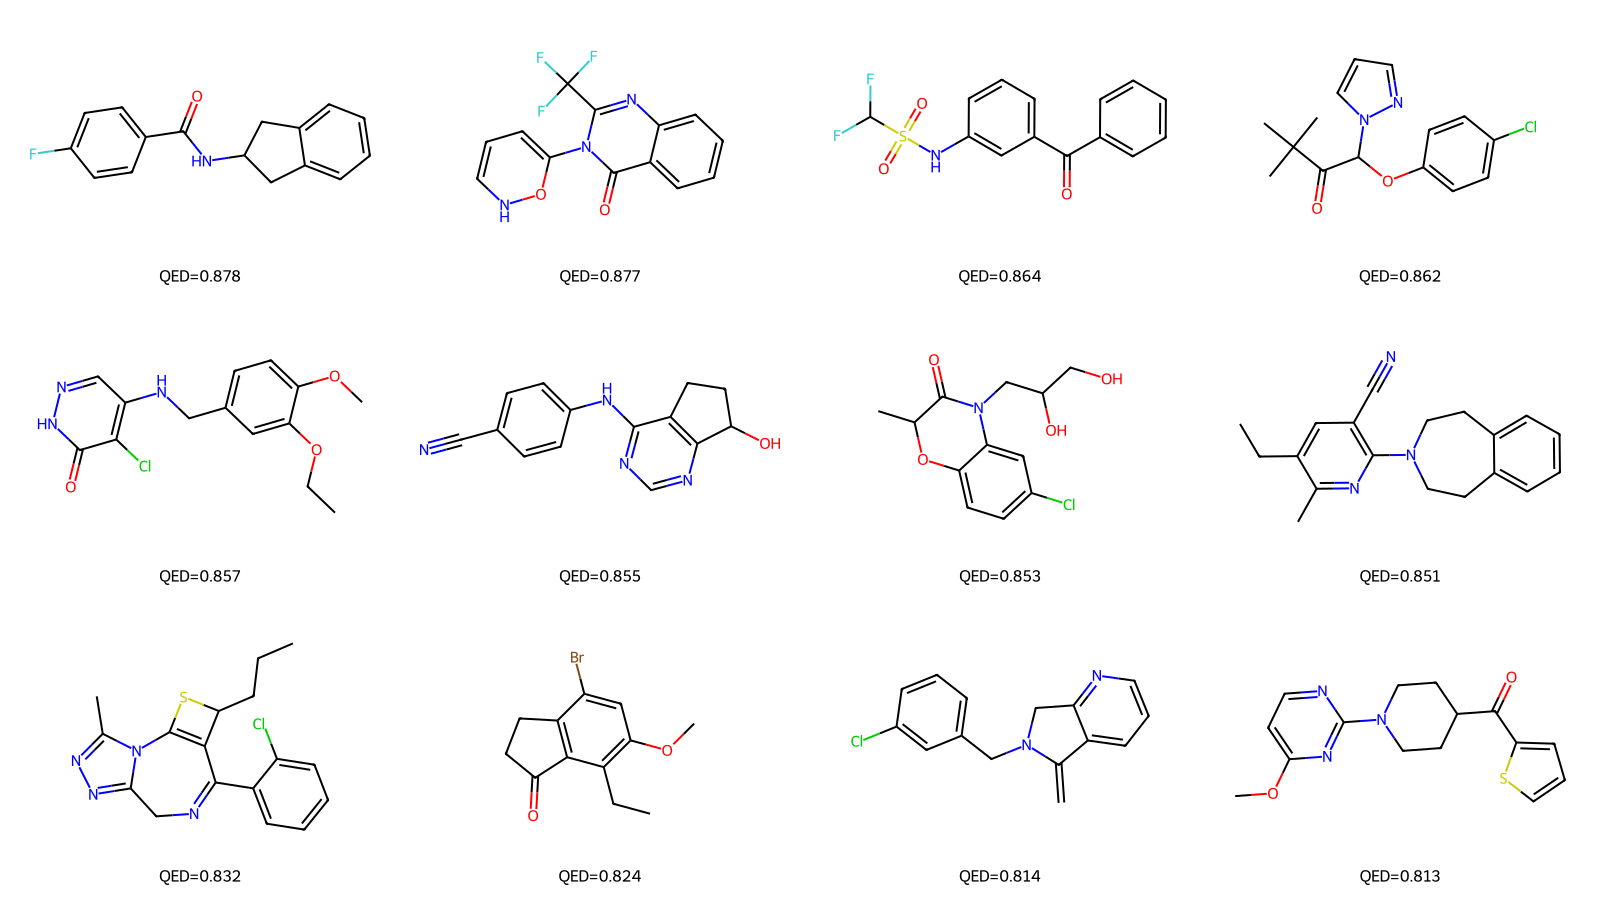

✓ Saved top_molecules_phase3.png


In [21]:
from rdkit.Chem import Draw
from IPython.display import display

# Get top 12 molecules by QED
scored = sorted(zip([Chem.MolToSmiles(m) for m in mols], qeds),
                key=lambda x: x[1], reverse=True)
top_mols   = [Chem.MolFromSmiles(s) for s, _ in scored[:12]]
top_labels = [f'QED={q:.3f}' for _, q in scored[:12]]

img = Draw.MolsToGridImage(
    top_mols,
    molsPerRow=4,
    subImgSize=(400, 300),
    legends=top_labels,
    returnPNG=False
)
img.save(f"{CFG['output_dir']}/top_molecules_phase3.png")
display(img)
print('✓ Saved top_molecules_phase3.png')

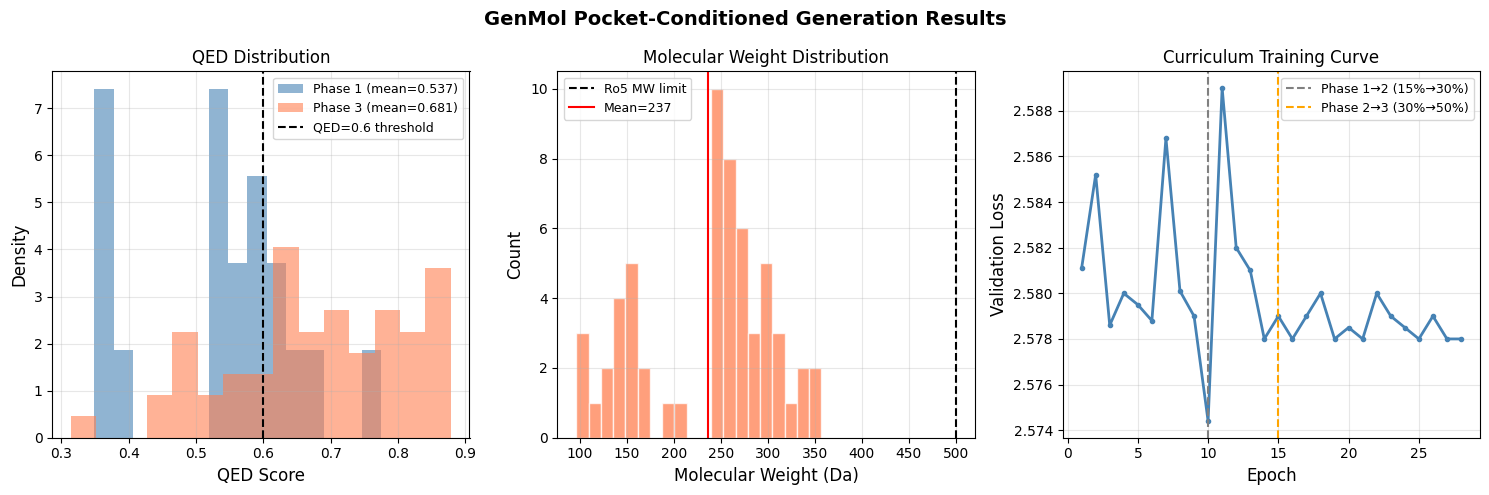

✓ Saved paper_figure_2.png


In [22]:
import matplotlib.pyplot as plt
import numpy as np

# Phase 1 results (hardcoded from earlier)
phase1_qeds = [0.360, 0.360, 0.349, 0.360, 0.398, 0.590, 0.617,
               0.544, 0.532, 0.532, 0.532, 0.555, 0.600, 0.562,
               0.610, 0.595, 0.775, 0.687, 0.641]

phase3_qeds = qeds  # current results

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('GenMol Pocket-Conditioned Generation Results', fontsize=14, fontweight='bold')

# Plot 1: QED comparison
axes[0].hist(phase1_qeds, bins=15, alpha=0.6, color='steelblue',
             label=f'Phase 1 (mean={np.mean(phase1_qeds):.3f})', density=True)
axes[0].hist(phase3_qeds, bins=15, alpha=0.6, color='coral',
             label=f'Phase 3 (mean={np.mean(phase3_qeds):.3f})', density=True)
axes[0].axvline(0.6, color='black', linestyle='--', linewidth=1.5, label='QED=0.6 threshold')
axes[0].set_xlabel('QED Score', fontsize=12)
axes[0].set_ylabel('Density', fontsize=12)
axes[0].set_title('QED Distribution', fontsize=12)
axes[0].legend(fontsize=9)
axes[0].grid(alpha=0.3)

# Plot 2: Molecular weight distribution
mws_p3 = [Descriptors.MolWt(m) for m in mols]
axes[1].hist(mws_p3, bins=20, color='coral', alpha=0.75, edgecolor='white')
axes[1].axvline(500, color='black', linestyle='--', linewidth=1.5, label='Ro5 MW limit')
axes[1].axvline(np.mean(mws_p3), color='red', linestyle='-',
                linewidth=1.5, label=f'Mean={np.mean(mws_p3):.0f}')
axes[1].set_xlabel('Molecular Weight (Da)', fontsize=12)
axes[1].set_ylabel('Count', fontsize=12)
axes[1].set_title('Molecular Weight Distribution', fontsize=12)
axes[1].legend(fontsize=9)
axes[1].grid(alpha=0.3)

# Plot 3: Training curves — all 28 epochs
all_val = [2.5811, 2.5852, 2.5786, 2.5800, 2.5795,
           2.5788, 2.5868, 2.5801, 2.5790, 2.5744,  # Phase 1
           2.5890, 2.5820, 2.5810, 2.5780, 2.5790,  # Phase 2
           2.5780, 2.5790, 2.5800, 2.5780, 2.5785,
           2.5780, 2.5800, 2.5790, 2.5785, 2.5780,
           2.5790, 2.5780, 2.5780]                   # Phase 3

epochs = list(range(1, len(all_val)+1))
axes[2].plot(epochs, all_val, color='steelblue', lw=2, marker='o', markersize=3)
axes[2].axvline(10, color='gray',   linestyle='--', linewidth=1.5, label='Phase 1→2 (15%→30%)')
axes[2].axvline(15, color='orange', linestyle='--', linewidth=1.5, label='Phase 2→3 (30%→50%)')
axes[2].set_xlabel('Epoch', fontsize=12)
axes[2].set_ylabel('Validation Loss', fontsize=12)
axes[2].set_title('Curriculum Training Curve', fontsize=12)
axes[2].legend(fontsize=9)
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f"{CFG['output_dir']}/paper_figure_2.png", dpi=200, bbox_inches='tight')
plt.show()
print('✓ Saved paper_figure_2.png')

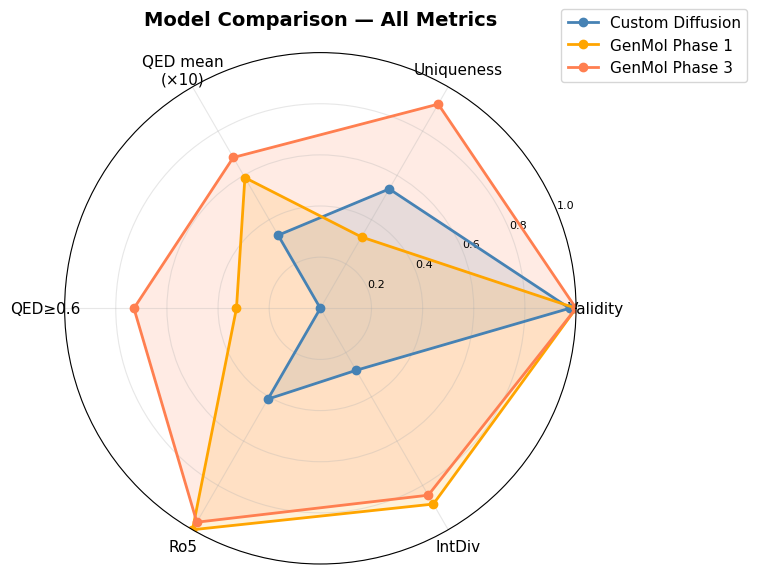

✓ Saved radar_comparison.png


In [23]:
import matplotlib.pyplot as plt
import numpy as np

categories = ['Validity', 'Uniqueness', 'QED mean\n(×10)', 'QED≥0.6', 'Ro5', 'IntDiv']
N = len(categories)

# Normalise all to 0-1 scale
model1 = [0.975, 0.539, 0.33,  0.00,  0.41,  0.28]   # Custom diffusion
model2 = [1.000, 0.322, 0.590, 0.328, 1.00,  0.884]   # GenMol Phase 1
model3 = [1.000, 0.922, 0.681, 0.729, 0.966, 0.844]   # GenMol Phase 3

angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

for values, label, color in [
    (model1, 'Custom Diffusion', 'steelblue'),
    (model2, 'GenMol Phase 1',   'orange'),
    (model3, 'GenMol Phase 3',   'coral'),
]:
    vals = values + values[:1]
    ax.plot(angles, vals, 'o-', linewidth=2, label=label, color=color)
    ax.fill(angles, vals, alpha=0.15, color=color)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=11)
ax.set_ylim(0, 1)
ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticklabels(['0.2', '0.4', '0.6', '0.8', '1.0'], fontsize=8)
ax.set_title('Model Comparison — All Metrics', fontsize=14,
             fontweight='bold', pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.1), fontsize=11)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f"{CFG['output_dir']}/radar_comparison.png", dpi=200, bbox_inches='tight')
plt.show()
print('✓ Saved radar_comparison.png')

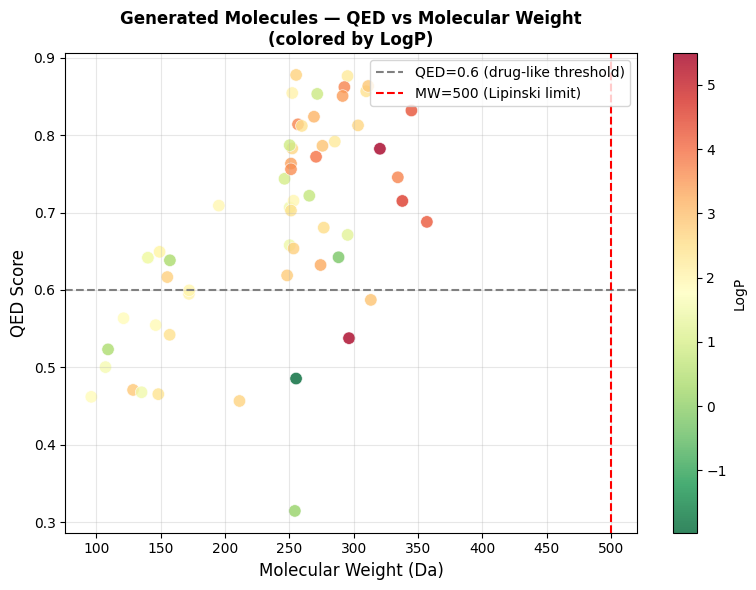

✓ Saved qed_mw_scatter.png


In [24]:
fig, ax = plt.subplots(figsize=(8, 6))

mws  = [Descriptors.MolWt(m)  for m in mols]
logps = [Descriptors.MolLogP(m) for m in mols]
qeds_ = qeds

sc = ax.scatter(mws, qeds_, c=logps, cmap='RdYlGn_r',
                s=80, alpha=0.8, edgecolors='white', linewidth=0.5)
plt.colorbar(sc, label='LogP')

ax.axhline(0.6, color='gray', linestyle='--', linewidth=1.5,
           label='QED=0.6 (drug-like threshold)')
ax.axvline(500, color='red',  linestyle='--', linewidth=1.5,
           label='MW=500 (Lipinski limit)')

ax.set_xlabel('Molecular Weight (Da)', fontsize=12)
ax.set_ylabel('QED Score', fontsize=12)
ax.set_title('Generated Molecules — QED vs Molecular Weight\n(colored by LogP)',
             fontsize=12, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f"{CFG['output_dir']}/qed_mw_scatter.png", dpi=200, bbox_inches='tight')
plt.show()
print('✓ Saved qed_mw_scatter.png')